In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "../dataset/synthetic_student_placement_dataset.csv"
)

print("Dataset loaded successfully!")

print(df.head())

Dataset loaded successfully!
  student_id  cgpa  tenth_percentage  twelfth_percentage  programming_score  \
0   STU00001   7.7              75.2                77.1                 89   
1   STU00002   6.4              74.7                85.8                 79   
2   STU00003   8.2              70.3                57.3                 43   
3   STU00004   8.3              82.7                71.6                 46   
4   STU00005   5.4              80.6                84.9                100   

   technical_score  communication_score  aptitude_score  \
0               34                   72              12   
1               28                   74              40   
2               72                   93              37   
3               27                   43              84   
4               28                   73              52   

   problem_solving_score  coding_score  ...  extracurricular_participation  \
0                     24            58  ...                    

In [7]:
import sys
print(sys.executable)

d:\Projects\placement-prediction\.venv-1\Scripts\python.exe


In [8]:
%pip install pandas numpy matplotlib seaborn scikit-learn xgboost

Note: you may need to restart the kernel to use updated packages.


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("All libraries imported successfully!")

All libraries imported successfully!


In [10]:
import pandas as pd
import numpy as np

df = pd.read_csv("../dataset/synthetic_student_placement_dataset.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [11]:
print("Rows and Columns:", df.shape)

Rows and Columns: (5000, 31)


In [12]:
df.describe()

,cgpa,tenth_percentage,twelfth_percentage,programming_score,technical_score,communication_score,aptitude_score,problem_solving_score,coding_score,sql_score,...,coding_problems_solved,attendance_percentage,teamwork_score,adaptability_score,leadership_score,python_skill,java_skill,web_development_skill,machine_learning_skill,cloud_skill
count,5000.000000,5000.000000,5000.000000,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,...,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,7.378300,77.896180,74.813320,60.07400,59.850200,60.654600,54.412800,57.730600,54.933400,54.956200,...,248.307000,81.767380,59.820400,60.173000,55.097400,49.991800,49.949400,50.315600,50.169200,49.325200
std,0.995722,10.908875,11.784568,23.55926,23.625219,23.441177,26.163129,24.537996,26.218475,26.194448,...,145.633309,9.769681,23.484157,23.205326,26.224368,29.004772,29.023889,28.865395,28.898311,29.036055
min,4.000000,35.000000,35.000000,20.00000,20.000000,20.000000,10.000000,15.000000,10.000000,10.000000,...,0.000000,47.700000,20.000000,20.000000,10.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,6.700000,70.700000,66.800000,39.00000,39.000000,40.000000,32.000000,37.000000,32.000000,32.000000,...,122.000000,75.000000,40.000000,40.000000,32.000000,25.000000,25.000000,26.000000,25.000000,25.000000
50%,7.400000,77.800000,74.600000,61.00000,60.000000,61.000000,54.000000,57.000000,55.000000,55.000000,...,247.000000,82.000000,59.000000,60.000000,55.000000,50.000000,50.000000,51.000000,50.000000,49.000000
75%,8.000000,85.400000,82.925000,80.00000,80.000000,82.000000,77.000000,79.000000,77.000000,78.000000,...,374.000000,88.800000,80.000000,80.000000,78.000000,75.000000,75.000000,75.000000,75.000000,74.000000
max,10.000000,100.000000,100.000000,100.00000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,...,500.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000


In [13]:
df["placement_status"].value_counts()

placement_status
Placed        3322
Not Placed    1678
Name: count, dtype: int64

In [14]:
df.isnull().sum()

student_id                          0
cgpa                                0
tenth_percentage                    0
twelfth_percentage                  0
programming_score                   0
technical_score                     0
communication_score                 0
aptitude_score                      0
problem_solving_score               0
coding_score                        0
sql_score                           0
domain_knowledge_score              0
interview_score                     0
resume_score                        0
projects_count                      0
internship_count                    0
certifications_count                0
backlog_count                       0
hackathons_participated             0
coding_problems_solved              0
attendance_percentage               0
extracurricular_participation    1195
teamwork_score                      0
adaptability_score                  0
leadership_score                    0
python_skill                        0
java_skill  

In [15]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 1195


In [16]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


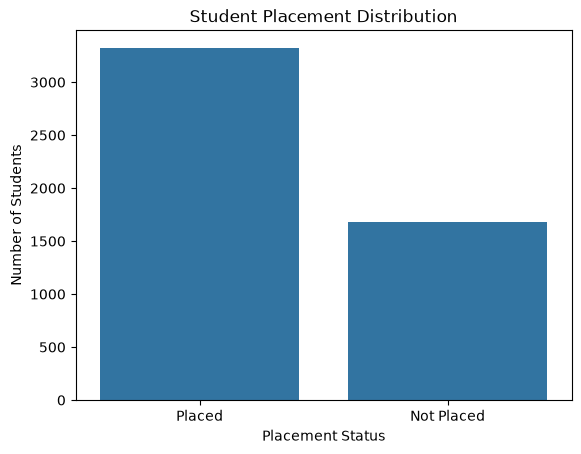

In [17]:
sns.countplot(data=df, x="placement_status")

plt.title("Student Placement Distribution")
plt.xlabel("Placement Status")
plt.ylabel("Number of Students")
plt.show()

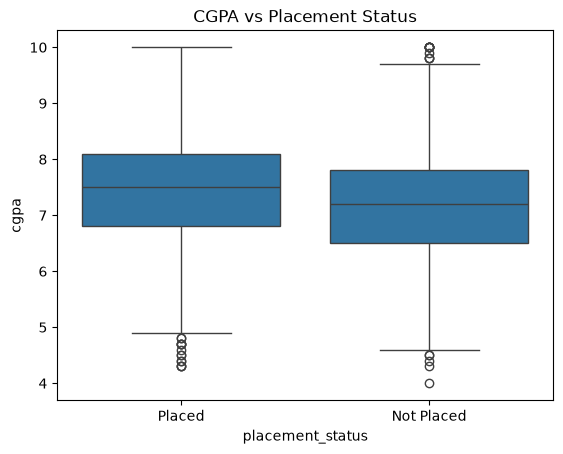

In [18]:
sns.boxplot(
    data=df,
    x="placement_status",
    y="cgpa"
)

plt.title("CGPA vs Placement Status")
plt.show()

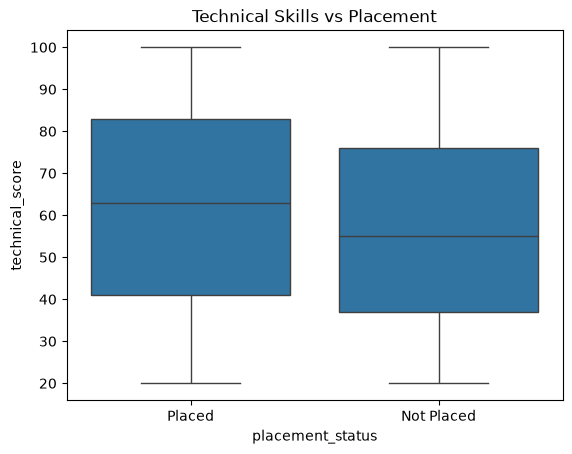

In [19]:
sns.boxplot(
    data=df,
    x="placement_status",
    y="technical_score"
)

plt.title("Technical Skills vs Placement")
plt.show()

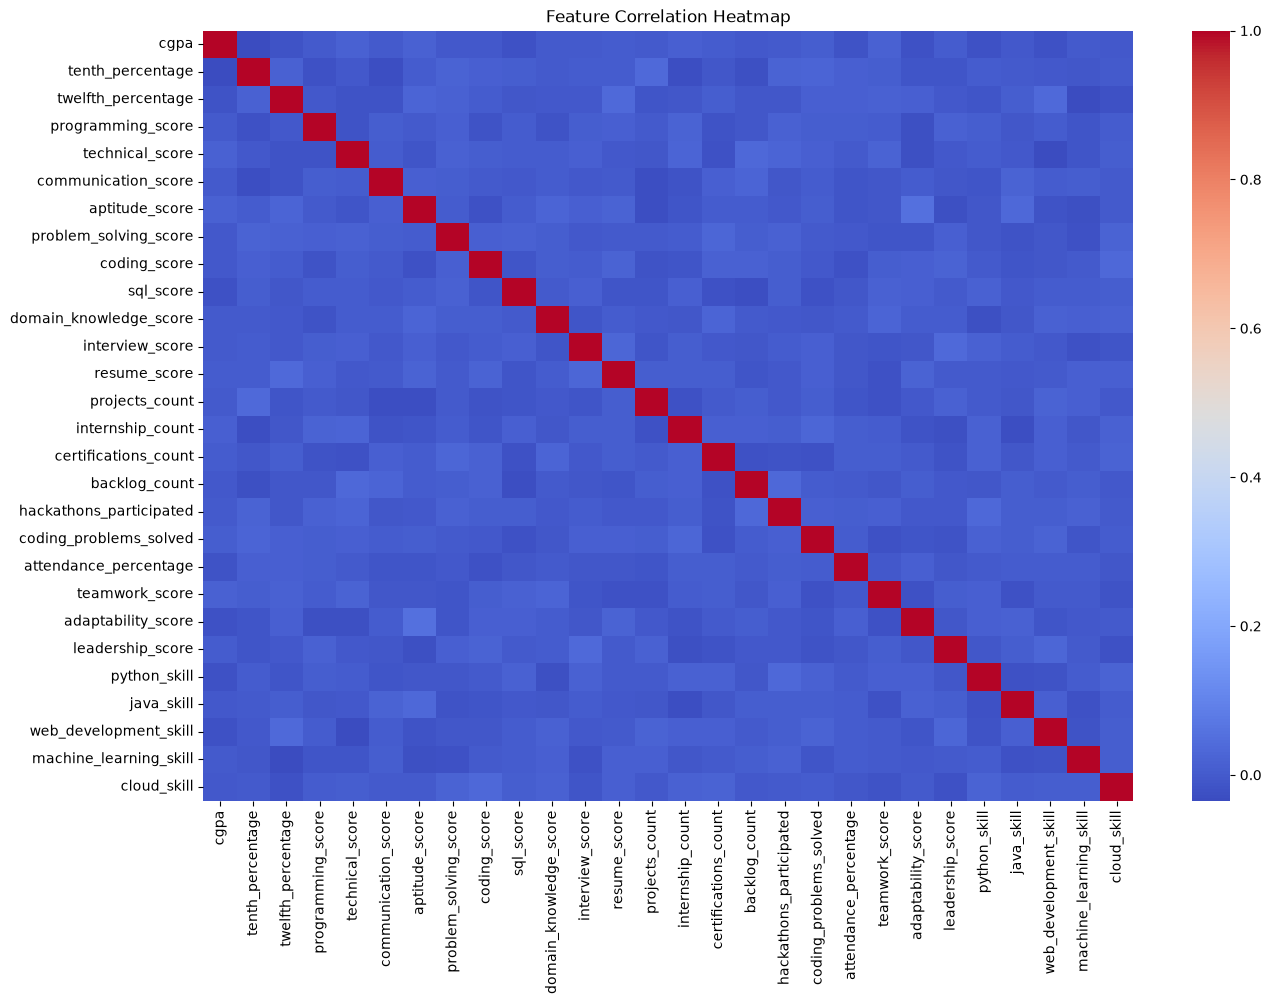

In [20]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(15, 10))

sns.heatmap(
    numeric_df.corr(),
    cmap="coolwarm",
    annot=False
)

plt.title("Feature Correlation Heatmap")
plt.show()

In [21]:
df["extracurricular_participation"].fillna(
    df["extracurricular_participation"].mode()[0],
    inplace=True
)

C:\Users\Sneha C V\AppData\Local\Temp\ipykernel_8820\792400813.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/docs/dev/user_guide/migration.html#copy-on-write-cow
  df["extracurricular_participation"].fillna(


0       Moderate
1       Moderate
2       Moderate
3       Moderate
4            Low
          ...   
4995    Moderate
4996         Low
4997    Moderate
4998    Moderate
4999        High
Name: extracurricular_participation, Length: 5000, dtype: str

In [22]:
print(df.isnull().sum().sum())

1195


In [23]:
print("Before:", df["extracurricular_participation"].isnull().sum())

df["extracurricular_participation"] = (
    df["extracurricular_participation"].fillna("Unknown")
)

print("After:", df["extracurricular_participation"].isnull().sum())

Before: 1195
After: 0


In [24]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


In [25]:
X = df.drop(columns=["placement_status", "student_id"])

y = df["placement_status"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (5000, 29)
Target shape: (5000,)


In [26]:
categorical_columns = X.select_dtypes(
    include=["object"]
).columns

numerical_columns = X.select_dtypes(
    exclude=["object"]
).columns

print("Categorical columns:", list(categorical_columns))

print("Numerical columns:", list(numerical_columns))

Categorical columns: ['extracurricular_participation']
Numerical columns: ['cgpa', 'tenth_percentage', 'twelfth_percentage', 'programming_score', 'technical_score', 'communication_score', 'aptitude_score', 'problem_solving_score', 'coding_score', 'sql_score', 'domain_knowledge_score', 'interview_score', 'resume_score', 'projects_count', 'internship_count', 'certifications_count', 'backlog_count', 'hackathons_participated', 'coding_problems_solved', 'attendance_percentage', 'teamwork_score', 'adaptability_score', 'leadership_score', 'python_skill', 'java_skill', 'web_development_skill', 'machine_learning_skill', 'cloud_skill']


C:\Users\Sneha C V\AppData\Local\Temp\ipykernel_8820\2552707666.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X.select_dtypes(
C:\Users\Sneha C V\AppData\Local\Temp\ipykernel_8820\2552707666.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are excluded by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `exclude` to remove them, or to `include` to keep them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html

In [27]:
from sklearn.preprocessing import OrdinalEncoder

encoder = OrdinalEncoder(
    categories=[["None", "Low", "Moderate", "High", "Unknown"]],
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

X[categorical_columns] = encoder.fit_transform(
    X[categorical_columns]
)

print(X.head())

   cgpa  tenth_percentage  twelfth_percentage  programming_score  \
0   7.7              75.2                77.1                 89   
1   6.4              74.7                85.8                 79   
2   8.2              70.3                57.3                 43   
3   8.3              82.7                71.6                 46   
4   5.4              80.6                84.9                100   

   technical_score  communication_score  aptitude_score  \
0               34                   72              12   
1               28                   74              40   
2               72                   93              37   
3               27                   43              84   
4               28                   73              52   

   problem_solving_score  coding_score  sql_score  ...  attendance_percentage  \
0                     24            58         18  ...                   85.9   
1                     22            50         24  ...                  10

In [28]:
y = y.map({
    "Not Placed": 0,
    "Placed": 1
})

print(y.head())

0    1
1    0
2    0
3    1
4    1
Name: placement_status, dtype: int64


In [29]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (4000, 29)
Testing data: (1000, 29)


In [30]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = X_train.copy()
X_test = X_test.copy()

X_train[numerical_columns] = scaler.fit_transform(
    X_train[numerical_columns]
)

X_test[numerical_columns] = scaler.transform(
    X_test[numerical_columns]
)

print("Feature scaling completed!")

Feature scaling completed!


In [31]:
print(X_train.shape)
print(X_test.shape)
print(y_train.value_counts())
print(y_test.value_counts())

(4000, 29)
(1000, 29)
placement_status
1    2658
0    1342
Name: count, dtype: int64
placement_status
1    664
0    336
Name: count, dtype: int64


In [32]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

In [33]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=6,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        eval_metric="logloss",
        random_state=42
    )
}

In [34]:
trained_models = {}

for name, model in models.items():

    model.fit(X_train, y_train)

    trained_models[name] = model

    print(name, "training completed!")

Logistic Regression training completed!
Decision Tree training completed!
Random Forest training completed!
XGBoost training completed!


In [35]:
predictions = {}

for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    predictions[name] = y_pred

    print(name, "prediction completed!")

Logistic Regression prediction completed!
Decision Tree prediction completed!
Random Forest prediction completed!
XGBoost prediction completed!


In [36]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = []

for name, y_pred in predictions.items():

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results)

print(results_df.round(3))

                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression     0.704      0.723   0.898     0.801
1        Decision Tree     0.650      0.680   0.895     0.772
2        Random Forest     0.673      0.675   0.979     0.799
3              XGBoost     0.685      0.711   0.886     0.789


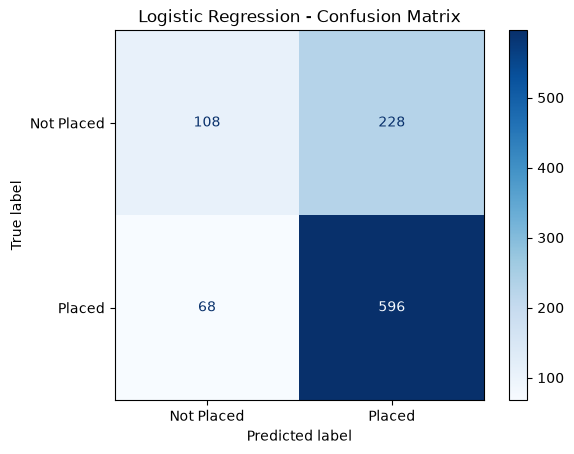

In [37]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

best_model = trained_models["Logistic Regression"]

y_pred = best_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Placed", "Placed"]
)

disp.plot(cmap="Blues")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

ROC-AUC Score: 0.721


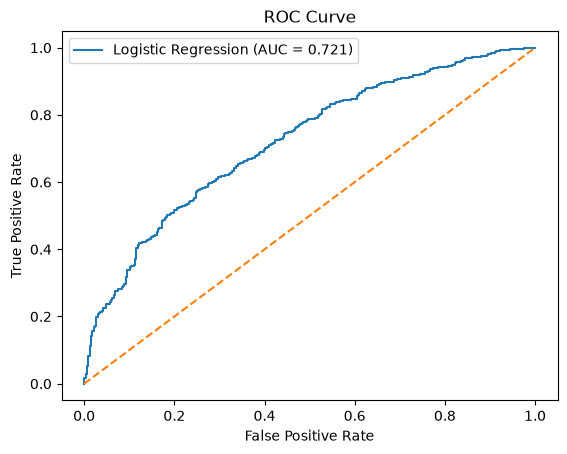

In [38]:
from sklearn.metrics import roc_auc_score, roc_curve

y_probability = best_model.predict_proba(X_test)[:, 1]

auc = roc_auc_score(y_test, y_probability)

print("ROC-AUC Score:", round(auc, 3))

fpr, tpr, thresholds = roc_curve(
    y_test, y_probability
)

plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

In [39]:
from sklearn.metrics import roc_auc_score

auc_results = []

for name, model in trained_models.items():

    probabilities = model.predict_proba(X_test)[:, 1]

    auc = roc_auc_score(y_test, probabilities)

    auc_results.append({
        "Model": name,
        "ROC-AUC": auc
    })

auc_df = pd.DataFrame(auc_results)

print(auc_df.sort_values(
    by="ROC-AUC",
    ascending=False
).round(3))

                 Model  ROC-AUC
0  Logistic Regression    0.721
2        Random Forest    0.702
3              XGBoost    0.698
1        Decision Tree    0.624


In [40]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate, StratifiedKFold

# Use the original, unencoded features
X_raw = df.drop(columns=["placement_status", "student_id"])

y = df["placement_status"].map({
    "Not Placed": 0,
    "Placed": 1
})

# Identify column types
numeric_cols = X_raw.select_dtypes(
    include=["number"]
).columns

categorical_cols = X_raw.select_dtypes(
    include=["object"]
).columns

# Preprocessing
preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_cols),
    ("categorical", OneHotEncoder(handle_unknown="ignore"),
     categorical_cols)
])

# Complete pipeline
pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

# Five-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_validate(
    pipeline,
    X_raw,
    y,
    cv=cv,
    scoring=["accuracy", "precision", "recall", "f1", "roc_auc"]
)

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    print(
        metric,
        round(scores[f"test_{metric}"].mean(), 3)
    )

C:\Users\Sneha C V\AppData\Local\Temp\ipykernel_8820\968673839.py:20: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_raw.select_dtypes(


accuracy 0.69
precision 0.715
recall 0.886
f1 0.792
roc_auc 0.698


In [41]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "model__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "model__solver": ["lbfgs", "liblinear"]
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

grid_search.fit(X_raw, y)

print("Best Parameters:", grid_search.best_params_)
print("Best CV Accuracy:", round(grid_search.best_score_, 3))

Best Parameters: {'model__C': 0.1, 'model__solver': 'lbfgs'}
Best CV Accuracy: 0.691


In [42]:
best_pipeline = grid_search.best_estimator_

feature_names = best_pipeline.named_steps[
    "preprocessing"
].get_feature_names_out()

coefficients = best_pipeline.named_steps[
    "model"
].coef_[0]

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Importance": np.abs(coefficients)
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df.head(15))

                                              Feature  Coefficient  Importance
13                            numeric__projects_count     0.394643    0.394643
16                             numeric__backlog_count    -0.370178    0.370178
0                                       numeric__cgpa     0.285248    0.285248
4                            numeric__technical_score     0.258515    0.258515
14                          numeric__internship_count     0.248765    0.248765
6                             numeric__aptitude_score     0.244746    0.244746
5                        numeric__communication_score     0.187414    0.187414
7                      numeric__problem_solving_score     0.178679    0.178679
18                    numeric__coding_problems_solved     0.178004    0.178004
27                               numeric__cloud_skill    -0.054045    0.054045
30  categorical__extracurricular_participation_Mod...    -0.052829    0.052829
29     categorical__extracurricular_participation_Lo

In [43]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

feature_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("selection", SelectKBest(
        score_func=f_classif,
        k=15
    )),
    ("model", LogisticRegression(
        C=0.1,
        solver="lbfgs",
        max_iter=1000
    ))
])

feature_scores = cross_val_score(
    feature_pipeline,
    X_raw,
    y,
    cv=cv,
    scoring="accuracy"
)

print("Feature Selection Accuracy:",
      round(feature_scores.mean(), 3))

Feature Selection Accuracy: 0.689


In [44]:
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", RandomForestClassifier(
        random_state=42,
        class_weight="balanced"
    ))
])

rf_params = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [5, 10, None],
    "model__min_samples_split": [2, 5]
}

rf_search = GridSearchCV(
    rf_pipeline,
    rf_params,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

rf_search.fit(X_raw, y)

print("Best Parameters:", rf_search.best_params_)
print("Best CV Accuracy:", round(rf_search.best_score_, 3))

Best Parameters: {'model__max_depth': None, 'model__min_samples_split': 5, 'model__n_estimators': 200}
Best CV Accuracy: 0.67


In [45]:
from xgboost import XGBClassifier

xgb_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", XGBClassifier(
        random_state=42,
        eval_metric="logloss"
    ))
])

xgb_params = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [3, 5],
    "model__learning_rate": [0.01, 0.1],
    "model__subsample": [0.8, 1.0]
}

xgb_search = GridSearchCV(
    xgb_pipeline,
    xgb_params,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

xgb_search.fit(X_raw, y)

print("Best Parameters:", xgb_search.best_params_)
print("Best CV Accuracy:", round(xgb_search.best_score_, 3))

Best Parameters: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 100, 'model__subsample': 0.8}
Best CV Accuracy: 0.685


In [46]:
final_models = {
    "Logistic Regression": grid_search.best_estimator_,
    "Random Forest": rf_search.best_estimator_,
    "XGBoost": xgb_search.best_estimator_
}

from sklearn.model_selection import cross_validate

for name, model in final_models.items():

    scores = cross_validate(
        model,
        X_raw,
        y,
        cv=cv,
        scoring=[
            "accuracy",
            "precision",
            "recall",
            "f1",
            "roc_auc"
        ]
    )

    print("\n", name)

    for metric in [
        "accuracy", "precision", "recall", "f1", "roc_auc"
    ]:
        print(
            metric,
            round(scores[f"test_{metric}"].mean(), 3)
        )


 Logistic Regression
accuracy 0.691
precision 0.715
recall 0.888
f1 0.792
roc_auc 0.698

 Random Forest
accuracy 0.67
precision 0.72
recall 0.824
f1 0.769
roc_auc 0.671

 XGBoost
accuracy 0.679
precision 0.705
recall 0.887
f1 0.786
roc_auc 0.676


In [47]:
import joblib
import os

# Create models folder
os.makedirs("../models", exist_ok=True)

# Save final trained model
joblib.dump(
    final_models,
    "../models/placement_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [48]:
loaded_model = joblib.load(
    "../models/placement_model.pkl"
)

print("Model loaded successfully!")

Model loaded successfully!


In [51]:
import joblib

final_model = joblib.load("../models/placement_model.pkl")

print(type(final_model))

<class 'dict'>


In [55]:
import joblib

loaded_model = joblib.load("../models/placement_model.pkl")

print("Object type:", type(loaded_model))
print("Available keys:", loaded_model.keys())

Object type: <class 'dict'>
Available keys: dict_keys(['Logistic Regression', 'Random Forest', 'XGBoost'])


In [56]:
for name, model in loaded_model.items():
    print("\nName:", name)
    print("Type:", type(model))


Name: Logistic Regression
Type: <class 'sklearn.pipeline.Pipeline'>

Name: Random Forest
Type: <class 'sklearn.pipeline.Pipeline'>

Name: XGBoost
Type: <class 'sklearn.pipeline.Pipeline'>


In [57]:
final_models = joblib.load("../models/placement_model.pkl")

final_model = final_models["Logistic Regression"]

print(type(final_model))

<class 'sklearn.pipeline.Pipeline'>


In [58]:
print(final_model.feature_names_in_)
print("Total features:", len(final_model.feature_names_in_))

['cgpa' 'tenth_percentage' 'twelfth_percentage' 'programming_score'
 'technical_score' 'communication_score' 'aptitude_score'
 'problem_solving_score' 'coding_score' 'sql_score'
 'domain_knowledge_score' 'interview_score' 'resume_score'
 'projects_count' 'internship_count' 'certifications_count'
 'backlog_count' 'hackathons_participated' 'coding_problems_solved'
 'attendance_percentage' 'extracurricular_participation' 'teamwork_score'
 'adaptability_score' 'leadership_score' 'python_skill' 'java_skill'
 'web_development_skill' 'machine_learning_skill' 'cloud_skill']
Total features: 29
